# Práctica 4 — Logística del Valle

## 1. Librerías y datos

In [27]:
from pathlib import Path
from collections import deque
from itertools import islice
import heapq, random, statistics, time
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

ARCHIVO = Path("Matriz_Logistica_del_Valle_40_nodos.csv")
if not ARCHIVO.exists():
    ARCHIVO = Path("/mnt/data/Matriz_Logistica_del_Valle_40_nodos.csv")
matriz = pd.read_csv(ARCHIVO, index_col=0, encoding="utf-8-sig")
assert matriz.shape == (40, 40), "Se esperaba una matriz de 40x40"
assert list(matriz.index) == list(matriz.columns), "Los nombres de filas y columnas no coinciden"
G = nx.DiGraph()
G.add_nodes_from(matriz.index)
for origen in matriz.index:
    for destino in matriz.columns:
        t = matriz.loc[origen, destino]
        if pd.notna(t) and float(t) > 0:
            G.add_edge(origen, destino, weight=float(t))
print(f"Grafo: {G.number_of_nodes()} nodos, {G.number_of_edges()} aristas dirigidas")
display(matriz.iloc[:8, :8])

Grafo: 40 nodos, 144 aristas dirigidas


,N01,N02,N03,N04,N05,N06,N07,N08
Origen/Destino,,,,,,,,
N01,0.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN
N02,8.0,0.0,8.0,NaN,NaN,NaN,NaN,NaN
N03,NaN,8.0,0.0,9.0,NaN,NaN,NaN,NaN
N04,NaN,NaN,9.0,0.0,10.0,NaN,NaN,NaN
N05,NaN,NaN,NaN,10.0,0.0,10.0,NaN,NaN
N06,NaN,NaN,NaN,NaN,10.0,0.0,7.0,NaN
N07,NaN,NaN,NaN,NaN,NaN,7.0,0.0,7.0
N08,NaN,NaN,NaN,NaN,NaN,NaN,7.0,0.0


## 2. Grafo y rutas registradas

In [28]:
rutas_actuales = {
    "N08": ["N01", "N02", "N03", "N04", "N05", "N06", "N07", "N08"],
    "N19": ["N01", "N02", "N03", "N11", "N19"],
    "N34": ["N01", "N09", "N17", "N25", "N33", "N34"],
    "N40": ["N01", "N02", "N03", "N04", "N05", "N06", "N07", "N08", "N16", "N24", "N32", "N40"]
}
DESTINOS = list(rutas_actuales)

def validar_ruta(g, ruta):
    if not ruta or len(ruta) < 2:
        return {"valida": False, "tiempo": None, "faltantes": []}
    faltantes = [(u,v) for u,v in zip(ruta, ruta[1:]) if not g.has_edge(u,v)]
    return {"valida": not faltantes,
            "tiempo": sum(g[u][v]["weight"] for u,v in zip(ruta,ruta[1:])) if not faltantes else None,
            "faltantes": faltantes}

filas=[]
for d,r in rutas_actuales.items():
    ida=validar_ruta(G,r); regreso=validar_ruta(G,r[::-1])
    filas.append({"Destino":d,"Ida válida":ida['valida'],"Ida (min)":ida['tiempo'],
                  "Regreso inverso válido":regreso['valida'],"Regreso (min)":regreso['tiempo'],
                  "Tramos inválidos de regreso":regreso['faltantes']})
tabla_originales=pd.DataFrame(filas)
display(tabla_originales)

,Destino,Ida válida,Ida (min),Regreso inverso válido,Regreso (min),Tramos inválidos de regreso
0,N08,True,59.0,True,59.0,[]
1,N19,True,33.0,True,33.0,[]
2,N34,True,42.0,True,42.0,[]
3,N40,True,93.0,True,93.0,[]


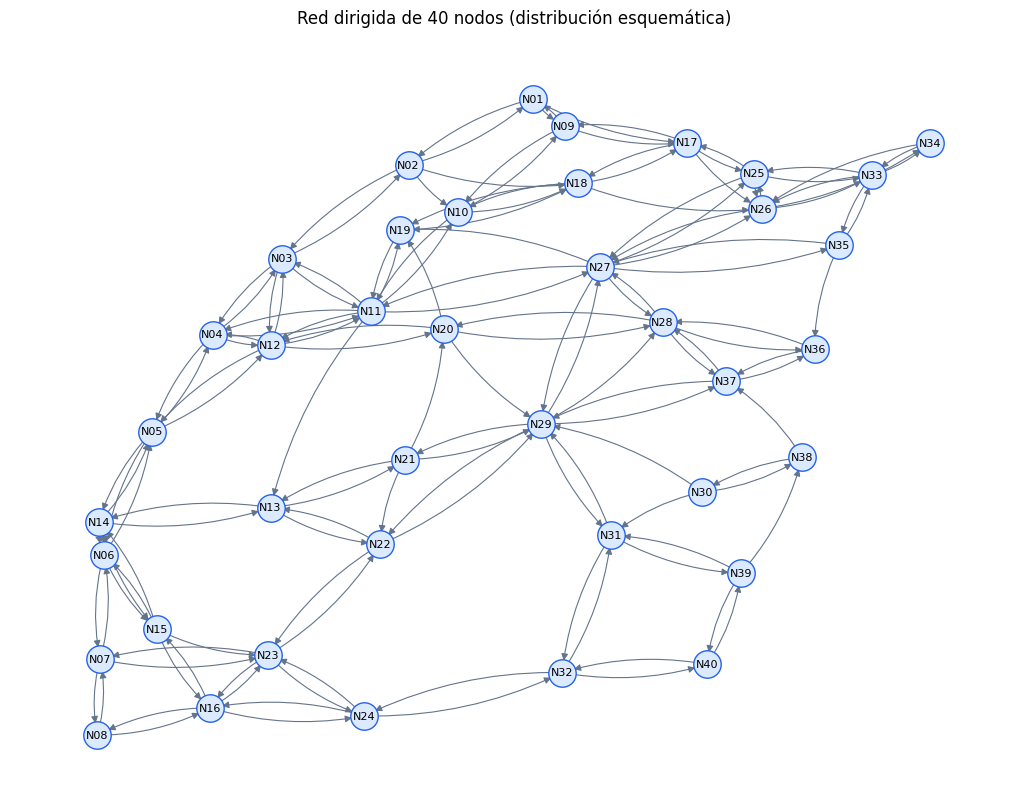

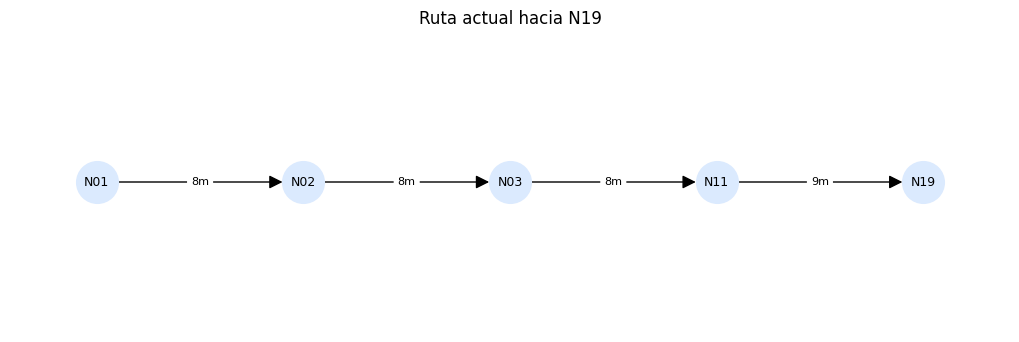

In [29]:
pos=nx.spring_layout(G, seed=42)
plt.figure(figsize=(13,10))
nx.draw_networkx_nodes(G,pos,node_size=390,node_color="#dbeafe",edgecolors="#2563eb")
nx.draw_networkx_labels(G,pos,font_size=8)
nx.draw_networkx_edges(G,pos,arrows=True,arrowsize=10,edge_color="#64748b",width=.8,connectionstyle="arc3,rad=0.12")
plt.title("Red dirigida de 40 nodos (distribución esquemática)")
plt.axis("off");plt.show()

def dibujar_ruta(g,ruta,titulo="Ruta"):
    if not validar_ruta(g,ruta)['valida']:
        print("Ruta inválida:",validar_ruta(g,ruta)['faltantes']);return
    h=nx.DiGraph();h.add_nodes_from(ruta)
    h.add_weighted_edges_from([(u,v,g[u][v]['weight']) for u,v in zip(ruta,ruta[1:])])
    p={v:(i,0) for i,v in enumerate(ruta)}
    plt.figure(figsize=(max(10,len(ruta)*1.4),3))
    nx.draw(h,p,with_labels=True,arrows=True,arrowsize=20,node_size=900,node_color="#dbeafe",font_size=9)
    nx.draw_networkx_edge_labels(h,p,edge_labels={(u,v):f"{w:g}m" for u,v,w in h.edges(data='weight')},font_size=8)
    plt.title(titulo);plt.axis('off');plt.show()

dibujar_ruta(G,rutas_actuales['N19'],"Ruta actual hacia N19")

## 3. Algoritmos BFS, DFS, Dijkstra y A*
BFS minimiza aristas; DFS encuentra una ruta válida; Dijkstra y A* minimizan tiempo. A* usa la cota admisible: saltos mínimos restantes × menor peso del grafo.

In [30]:
def buscar_bfs(g, origen, destino):
    cola=deque([[origen]]);vistos={origen};explorados=0
    while cola:
        r=cola.popleft();u=r[-1];explorados+=1
        if u==destino:return r,explorados
        for v in g.successors(u):
            if v not in vistos:vistos.add(v);cola.append(r+[v])
    return None,explorados

def buscar_dfs(g, origen, destino):
    pila=[[origen]];vistos=set();explorados=0
    while pila:
        r=pila.pop();u=r[-1]
        if u in vistos:continue
        vistos.add(u);explorados+=1
        if u==destino:return r,explorados
        for v in g.successors(u):
            if v not in vistos:pila.append(r+[v])
    return None,explorados

def buscar_dijkstra(g, origen, destino):
    cola=[(0,origen,[origen])];mejor={origen:0};explorados=0
    while cola:
        costo,u,r=heapq.heappop(cola)
        if costo>mejor[u]:continue
        explorados+=1
        if u==destino:return r,explorados
        for v in g.successors(u):
            nuevo=costo+g[u][v]['weight']
            if nuevo<mejor.get(v,float('inf')):
                mejor[v]=nuevo;heapq.heappush(cola,(nuevo,v,r+[v]))
    return None,explorados

def calcular_heuristicas(g,destino):
    minimo=min(w for _,_,w in g.edges(data='weight'))
    saltos=nx.single_source_shortest_path_length(g.reverse(copy=False),destino)
    return {n:pasos*minimo for n,pasos in saltos.items()}

def buscar_astar(g, origen, destino, heuristicas=None):
    if heuristicas is None:heuristicas=calcular_heuristicas(g,destino)
    cola=[(heuristicas.get(origen,float('inf')),0,origen,[origen])]
    mejor={origen:0};explorados=0
    while cola:
        f,costo,u,r=heapq.heappop(cola)
        if costo>mejor[u]:continue
        explorados+=1
        if u==destino:return r,explorados
        for v in g.successors(u):
            nuevo=costo+g[u][v]['weight']
            if nuevo<mejor.get(v,float('inf')):
                mejor[v]=nuevo
                heapq.heappush(cola,(nuevo+heuristicas.get(v,float('inf')),nuevo,v,r+[v]))
    return None,explorados

ALGORITMOS={"BFS":buscar_bfs,"DFS":buscar_dfs,"Dijkstra":buscar_dijkstra,"A*":buscar_astar}
comparacion=[]
for d in DESTINOS:
    for sentido,o,t in [("Ida","N01",d),("Regreso",d,"N01")]:
        for nombre,funcion in ALGORITMOS.items():
            ruta,explorados=funcion(G,o,t)
            comparacion.append({"Destino":d,"Sentido":sentido,"Algoritmo":nombre,
                                "Ruta":' → '.join(ruta) if ruta else 'Sin ruta',
                                "Tiempo (min)":validar_ruta(G,ruta)['tiempo'] if ruta else None,
                                "Nodos explorados":explorados})
tabla_algoritmos=pd.DataFrame(comparacion)
display(tabla_algoritmos.pivot_table(index=['Destino','Sentido'],columns='Algoritmo',values='Tiempo (min)'))
assert all(abs(tabla_algoritmos.query('Algoritmo == "Dijkstra"')['Tiempo (min)'].to_numpy()-tabla_algoritmos.query('Algoritmo == "A*"')['Tiempo (min)'].to_numpy())<1e-9)

Algoritmo          A*   BFS    DFS  Dijkstra
Destino Sentido                             
N08     Ida      51.0  59.0  215.0      51.0
        Regreso  59.0  59.0  240.0      59.0
N19     Ida      18.0  18.0  142.0      18.0
        Regreso  24.0  33.0  222.0      24.0
N34     Ida      24.0  24.0   24.0      24.0
        Regreso  34.0  34.0  222.0      34.0
N40     Ida      47.0  47.0   78.0      47.0
        Regreso  61.0  62.0  237.0      61.0

## 4. Validación de alternativas
Se seleccionan dos rutas alternativas **distintas de la ruta actual**, priorizando las más rápidas. El regreso se calcula de forma independiente y puede diferir de la inversión de la ida.

In [31]:
def alternativas(g, origen, destino, excluidas=(), cantidad=2):
    excluidas={tuple(r) for r in excluidas}
    salida=[]
    try:
        generador=nx.shortest_simple_paths(g,origen,destino,weight='weight')
        for r in generador:
            if tuple(r) in excluidas:continue
            salida.append(r)
            if len(salida)==cantidad:break
    except (nx.NetworkXNoPath,nx.NodeNotFound):pass
    return salida

filas=[]; politica_actual={};politica_mejorada={}
for d,actual in rutas_actuales.items():
    # La política actual usa el retorno inverso si existe; si no, se documenta
    # una ruta de regreso viable de menor tiempo para no simular viajes imposibles.
    inversa=actual[::-1]
    regreso_actual=inversa if validar_ruta(G,inversa)['valida'] else buscar_dijkstra(G,d,'N01')[0]
    politica_actual[d]=(actual,regreso_actual)
    opt_ida=buscar_dijkstra(G,'N01',d)[0]
    opt_reg=buscar_dijkstra(G,d,'N01')[0]
    politica_mejorada[d]=(opt_ida,opt_reg)
    for sentido,o,t,r_actual in [('Ida','N01',d,actual),('Regreso',d,'N01',inversa)]:
        candidatos=alternativas(G,o,t,excluidas=[r_actual],cantidad=2)
        opciones=[('Actual registrada',r_actual)]+[(f'Alternativa {i}',r) for i,r in enumerate(candidatos,1)]
        for etiqueta,r in opciones:
            v=validar_ruta(G,r)
            filas.append({'Destino':d,'Sentido':sentido,'Tipo':etiqueta,
                          'Ruta':' → '.join(r),'Válida':v['valida'],'Tiempo (min)':v['tiempo']})
tabla_alternativas=pd.DataFrame(filas)
display(tabla_alternativas)
print('Nota: cuando el regreso registrado es inválido, la simulación usa un retorno viable de Dijkstra; no se atribuye ese retorno a la empresa.')

,Destino,Sentido,Tipo,Ruta,Válida,Tiempo (min)
0,N08,Ida,Actual registrada,N01 → N02 → N03 → N04 → N05 → N06 → N07 → N08,True,59.0
1,N08,Ida,Alternativa 1,N01 → N09 → N10 → N11 → N13 → N22 → N23 → N07 ...,True,51.0
2,N08,Ida,Alternativa 2,N01 → N02 → N03 → N11 → N13 → N22 → N23 → N07 ...,True,52.0
3,N08,Regreso,Actual registrada,N08 → N07 → N06 → N05 → N04 → N03 → N02 → N01,True,59.0
4,N08,Regreso,Alternativa 1,N08 → N07 → N06 → N05 → N12 → N03 → N02 → N01,True,59.0
5,N08,Regreso,Alternativa 2,N08 → N07 → N23 → N22 → N29 → N27 → N11 → N10 ...,True,62.0
6,N19,Ida,Actual registrada,N01 → N02 → N03 → N11 → N19,True,33.0
7,N19,Ida,Alternativa 1,N01 → N02 → N18 → N19,True,18.0
8,N19,Ida,Alternativa 2,N01 → N17 → N18 → N19,True,20.0
9,N19,Regreso,Actual registrada,N19 → N11 → N03 → N02 → N01,True,33.0


Nota: cuando el regreso registrado es inválido, la simulación usa un retorno viable de Dijkstra; no se atribuye ese retorno a la empresa.


## 5. Modelo de simulación de eventos discretos
**Supuestos adicionales explícitos:** llegadas Poisson (intervalos exponenciales), destinos equiprobables, tiempo de entrega en destino = 0 min (no proporcionado), tiempos de viaje deterministas según matriz, vehículos idénticos, FIFO, sin turnos de conductores ni carga/descarga. La puntualidad se mide **al llegar al destino**, incluida la espera; el vehículo solo queda libre después de regresar. Se aceptan pedidos durante las horas configuradas y se termina de atender la cola aunque la jornada haya concluido.

In [ ]:
ESCENARIOS={'Normal':4,'Semana Santa':6,'Navidad':10}

def generar_pedidos(tasa_hora=4, horas=8, semilla=42):
    if tasa_hora<=0 or horas<=0:raise ValueError('Tasa y horas deben ser positivas')
    rng=random.Random(semilla);pedidos=[];t=0.;limite=horas*60
    while True:
        t+=rng.expovariate(tasa_hora/60)
        if t>limite:break
        pedidos.append({'id':len(pedidos)+1,'llegada':t,'destino':rng.choice(DESTINOS)})
    return pedidos

def simular(pedidos, politica, vehiculos=8, tiempo_servicio=0):
    if vehiculos<1 or tiempo_servicio<0:raise ValueError('Parámetros inválidos')
    # Cola de disponibilidad: cada vehículo comienza libre en t=0.
    libres=[(0.,i) for i in range(vehiculos)];heapq.heapify(libres)
    registros=[];ocupacion=0.
    for pedido in pedidos:
        libre,vehiculo=heapq.heappop(libres)
        inicio=max(libre,pedido['llegada'])
        ida,regreso=politica[pedido['destino']]
        t_ida=validar_ruta(G_sim,ida)['tiempo']
        t_reg=validar_ruta(G_sim,regreso)['tiempo']
        if t_ida is None or t_reg is None:
            raise ValueError(f'Ruta inválida para {pedido["destino"]}')
        entrega=inicio+t_ida
        disponible=entrega+tiempo_servicio+t_reg
        heapq.heappush(libres,(disponible,vehiculo))
        ocupacion+=t_ida+tiempo_servicio+t_reg
        registros.append({'id':pedido['id'],'destino':pedido['destino'],
                          'llegada':pedido['llegada'],'inicio':inicio,'entrega':entrega,
                          'fin_ciclo':disponible,'espera':inicio-pedido['llegada'],
                          'respuesta':entrega-pedido['llegada'],
                          'puntual':entrega-pedido['llegada']<=75})
    df=pd.DataFrame(registros)
    fin=max([p['fin_ciclo'] for p in registros],default=0.)
    return {'detalle':df,'pedidos':len(df),'puntuales':int(df['puntual'].sum()) if len(df) else 0,
            'espera_promedio':df['espera'].mean() if len(df) else 0.,
            'respuesta_promedio':df['respuesta'].mean() if len(df) else 0.,
            'utilizacion':ocupacion/(vehiculos*fin) if fin>0 else 0.,
            'fin':fin,'extra_min':max(0,fin-8*60)}

# Grafo activo
G_sim=G.copy()

def construir_politicas(g):
    actual={};mejorada={}
    for d,r in rutas_actuales.items():
        # Si la ruta registrada se cierra, no se puede usar la política original.
        if not validar_ruta(g,r)['valida']:
            raise ValueError(f'La ruta original hacia {d} está interrumpida; defina política de contingencia')
        inversa=r[::-1]
        retorno=inversa if validar_ruta(g,inversa)['valida'] else nx.shortest_path(g,d,'N01',weight='weight')
        actual[d]=(r,retorno)
        mejorada[d]=(nx.shortest_path(g,'N01',d,weight='weight'),nx.shortest_path(g,d,'N01',weight='weight'))
    return actual,mejorada

def incidente(g,origen,destino,nuevo_tiempo=None,cerrar=False):
    mod=g.copy()
    if not mod.has_edge(origen,destino):raise ValueError('Conexión inexistente')
    if cerrar:mod.remove_edge(origen,destino)
    else:
        if nuevo_tiempo is None or nuevo_tiempo<=0:raise ValueError('Tiempo debe ser positivo')
        mod[origen][destino]['weight']=float(nuevo_tiempo)
    return mod

pedidos=generar_pedidos(4,8,42)
politica_actual,politica_mejorada=construir_politicas(G_sim)
for nombre,pol in [('Actual',politica_actual),('Mejorada',politica_mejorada)]:
    res=simular(pedidos,pol)
    print(nombre,{k:round(v,3) if isinstance(v,float) else v for k,v in res.items() if k!='detalle'})

Actual {'pedidos': 34, 'puntuales': 27, 'espera_promedio': np.float64(5.212), 'respuesta_promedio': np.float64(58.595), 'utilizacion': 0.665, 'fin': 682.396, 'extra_min': 202.396}
Mejorada {'pedidos': 34, 'puntuales': 34, 'espera_promedio': np.float64(0.518), 'respuesta_promedio': np.float64(36.018), 'utilizacion': 0.587, 'fin': 579.078, 'extra_min': 99.078}


## 6. Experimentos pareados y resultados
Cinco repeticiones como mínimo por escenario. Cada pareja actual/mejorada recibe **exactamente los mismos pedidos, destinos y tiempos de llegada**. La utilización se calcula sobre el horizonte hasta que vuelve el último vehículo. El tiempo adicional se mide después de las ocho horas, por defecto.

,Escenario,Política,Pedidos,Puntuales,Espera promedio (min),Solicitud a entrega (min),Utilización (%),Tiempo extra (min)
0,Navidad,Actual,73.8,8.4,266.70,325.01,89.55,719.73
1,Navidad,Mejorada,73.8,17.6,118.68,153.70,90.22,332.32
2,Normal,Actual,27.0,16.2,11.11,69.01,63.94,132.05
3,Normal,Mejorada,27.0,26.6,1.77,37.32,50.05,63.71
4,Semana Santa,Actual,45.2,12.6,70.64,129.34,81.49,334.85
5,Semana Santa,Mejorada,45.2,35.4,15.67,50.59,71.77,143.57


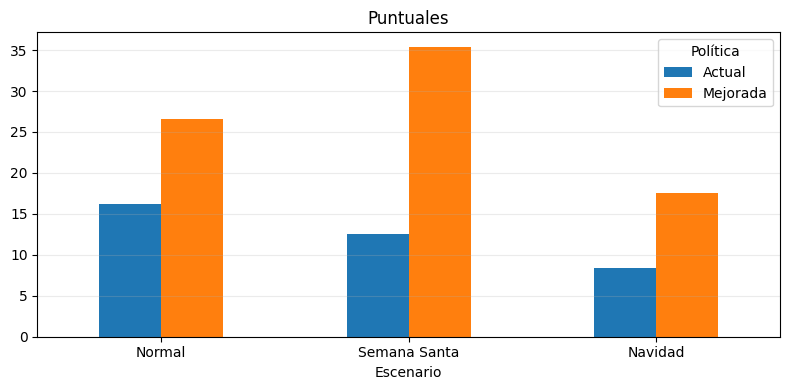

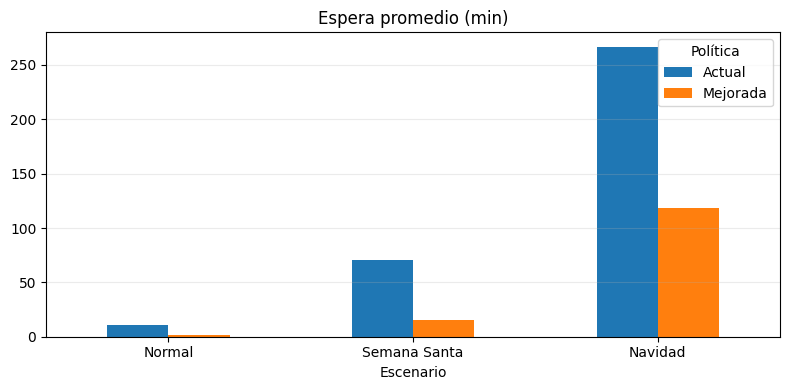

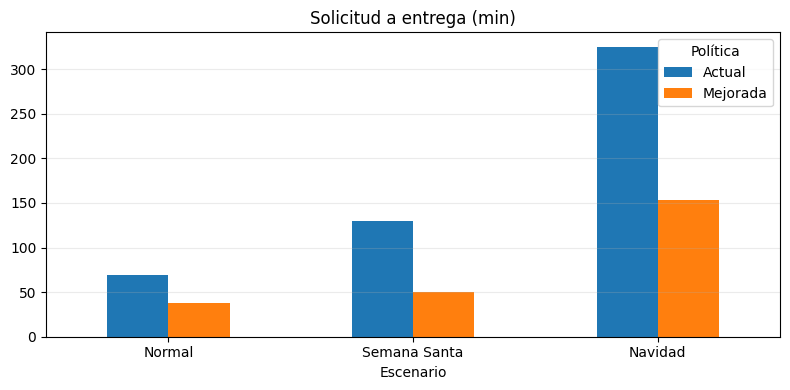

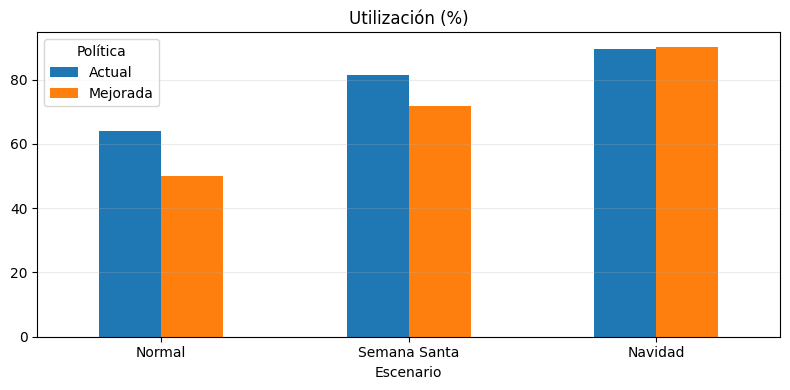

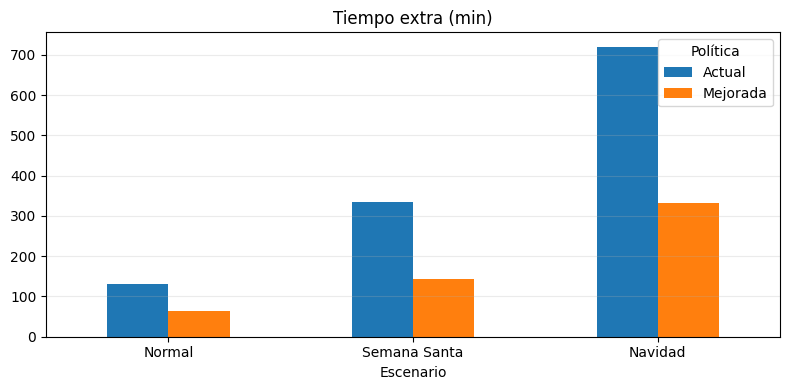

In [33]:
def experimentar(g=G, tasas=ESCENARIOS, vehiculos=8, horas=8, semillas=range(100,105), tiempo_servicio=0):
    global G_sim
    G_sim=g
    actual,mejorada=construir_politicas(g)
    filas=[]
    for escenario,tasa in tasas.items():
        for semilla in semillas:
            pedidos=generar_pedidos(tasa,horas,semilla)
            for nombre,pol in [('Actual',actual),('Mejorada',mejorada)]:
                res=simular(pedidos,pol,vehiculos,tiempo_servicio)
                filas.append({'Escenario':escenario,'Semilla':semilla,'Política':nombre,
                              'Pedidos':res['pedidos'],'Puntuales':res['puntuales'],
                              'Espera promedio (min)':res['espera_promedio'],
                              'Solicitud a entrega (min)':res['respuesta_promedio'],
                              'Utilización (%)':res['utilizacion']*100,
                              'Tiempo extra (min)':max(0,res['fin']-horas*60)})
    return pd.DataFrame(filas)

resultados=experimentar()
resumen=resultados.groupby(['Escenario','Política'],as_index=False).mean(numeric_only=True).drop(columns='Semilla')
display(resumen.round(2))
for metrica in ['Puntuales','Espera promedio (min)','Solicitud a entrega (min)','Utilización (%)','Tiempo extra (min)']:
    piv=resumen.pivot(index='Escenario',columns='Política',values=metrica)
    ax=piv.reindex(list(ESCENARIOS)).plot(kind='bar',figsize=(8,4),rot=0,title=metrica)
    ax.set_xlabel('Escenario');ax.grid(axis='y',alpha=.25);plt.tight_layout();plt.show()

## 7. Interfaz configurable (Jupyter)
La siguiente celda habilita controles con `ipywidgets` si está instalado. En caso contrario, utilice la función `ejecutar_configuracion` con parámetros explícitos. Las conexiones modificadas recalculan las rutas mejoradas; si se interrumpe una ruta original, se informa que esa política ya no es aplicable.

In [35]:
def ejecutar_configuracion(escenario='Normal',tasa=None,vehiculos=8,horas=8,semilla=42,
                          origen_incidente=None,destino_incidente=None,nuevo_tiempo=None,cerrar=False):
    g=G.copy()
    if origen_incidente and destino_incidente:
        g=incidente(g,origen_incidente,destino_incidente,nuevo_tiempo,cerrar)
    tasa=ESCENARIOS[escenario] if tasa is None else tasa
    global G_sim
    G_sim=g
    actual,mejorada=construir_politicas(g)
    pedidos=generar_pedidos(tasa,horas,semilla)
    filas=[]
    for nombre,pol in [('Actual',actual),('Mejorada',mejorada)]:
        r=simular(pedidos,pol,vehiculos)
        filas.append({'Política':nombre,'Pedidos':r['pedidos'],'Puntuales':r['puntuales'],
                      'Espera media':r['espera_promedio'],'Solicitud-entrega':r['respuesta_promedio'],
                      'Utilización %':100*r['utilizacion'],'Extra (min)':max(0,r['fin']-horas*60)})
    return pd.DataFrame(filas)

try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    escenario=widgets.Dropdown(options=list(ESCENARIOS),description='Escenario')
    tasa=widgets.FloatText(value=4,description='Pedidos/h')
    veh=widgets.IntSlider(value=8,min=1,max=30,description='Vehículos')
    horas=widgets.FloatSlider(value=8,min=1,max=16,description='Horas')
    semilla=widgets.IntText(value=42,description='Semilla')
    origen=widgets.Dropdown(options=['(ninguno)']+list(G.nodes),description='Origen tramo')
    destino=widgets.Dropdown(options=['(ninguno)']+list(G.nodes),description='Destino tramo')
    cierre=widgets.Checkbox(value=False,description='Cerrar conexión')
    nuevo=widgets.FloatText(value=8,description='Nuevo tiempo')
    boton=widgets.Button(description='Simular',button_style='primary')
    salida=widgets.Output()
    def actualizar_tasa(change):tasa.value=ESCENARIOS[change['new']]
    escenario.observe(actualizar_tasa,names='value')
    def ejecutar(_):
        with salida:
            clear_output(wait=True)
            try:
                display(ejecutar_configuracion(escenario.value,tasa.value,veh.value,horas.value,semilla.value,
                    None if origen.value=='(ninguno)' else origen.value,
                    None if destino.value=='(ninguno)' else destino.value,nuevo.value,cierre.value).round(2))
            except (ValueError,nx.NetworkXNoPath) as e:print('No se puede simular:',e)
    boton.on_click(ejecutar)
    display(widgets.VBox([widgets.HBox([escenario,tasa,veh]),widgets.HBox([horas,semilla]),
                          widgets.HBox([origen,destino,cierre,nuevo]),boton,salida]))
except ImportError:
    print('Para usar controles interactivos: pip install ipywidgets')
    display(ejecutar_configuracion().round(2))

Para usar controles interactivos: pip install ipywidgets


,Política,Pedidos,Puntuales,Espera media,Solicitud-entrega,Utilización %,Extra (min)
0,Actual,34,27,5.21,58.59,66.49,202.40
1,Mejorada,34,34,0.52,36.02,58.67,99.08
